array([[<Axes: xlabel='Date'>],
       [<Axes: xlabel='Date'>]], dtype=object)

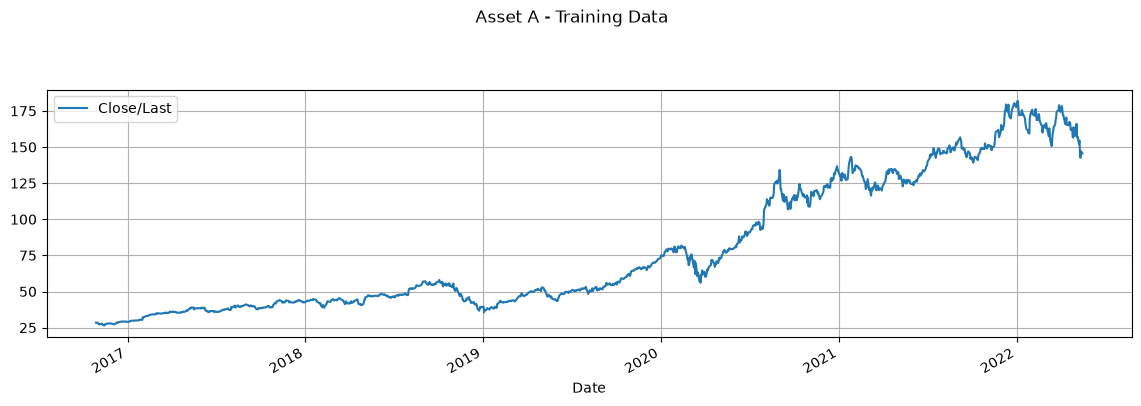

In [48]:
import pandas as pd
import numpy as np

training_data = pd.read_csv("../Data/EvaluationData/Training/Asset_A_train.csv", parse_dates=["Date"]).sort_values("Date")
training_data["Close/Last"] = pd.to_numeric(training_data["Close/Last"].astype(str).str.replace(r"[$,]", "", regex=True), )

training_data.plot(x='Date', y='Close/Last', subplots=True, layout=(2, 1), figsize=(14, 8), grid = True, title="Asset A - Training Data")

,Date,Close/Last,Volume,Open,High,Low,close_log_return,close_simple_return
0,2016-10-28,28.4300,147168400,$28.4675,$28.8025,$28.3625,NaN,NaN
1,2016-10-31,28.3850,105515640,$28.4125,$28.5575,$28.30,-0.001584,-0.001583
2,2016-11-01,27.8725,173615040,$28.365,$28.4425,$27.6325,-0.018220,-0.018055
3,2016-11-02,27.8975,112699920,$27.85,$28.0875,$27.8075,0.000897,0.000897
4,2016-11-03,27.4575,106154800,$27.745,$27.865,$27.3875,-0.015898,-0.015772
...,...,...,...,...,...,...,...,...
1391,2022-05-10,154.5100,115366700,$155.52,$156.74,$152.93,0.015984,0.016112
1392,2022-05-11,146.5000,142689800,$153.50,$155.45,$145.81,-0.053233,-0.051841
1393,2022-05-12,142.5600,182602000,$142.77,$146.20,$138.80,-0.027262,-0.026894
1394,2022-05-13,147.1100,113990900,$144.59,$148.105,$143.11,0.031418,0.031916


array([[<Axes: xlabel='Date'>],
       [<Axes: xlabel='Date'>]], dtype=object)

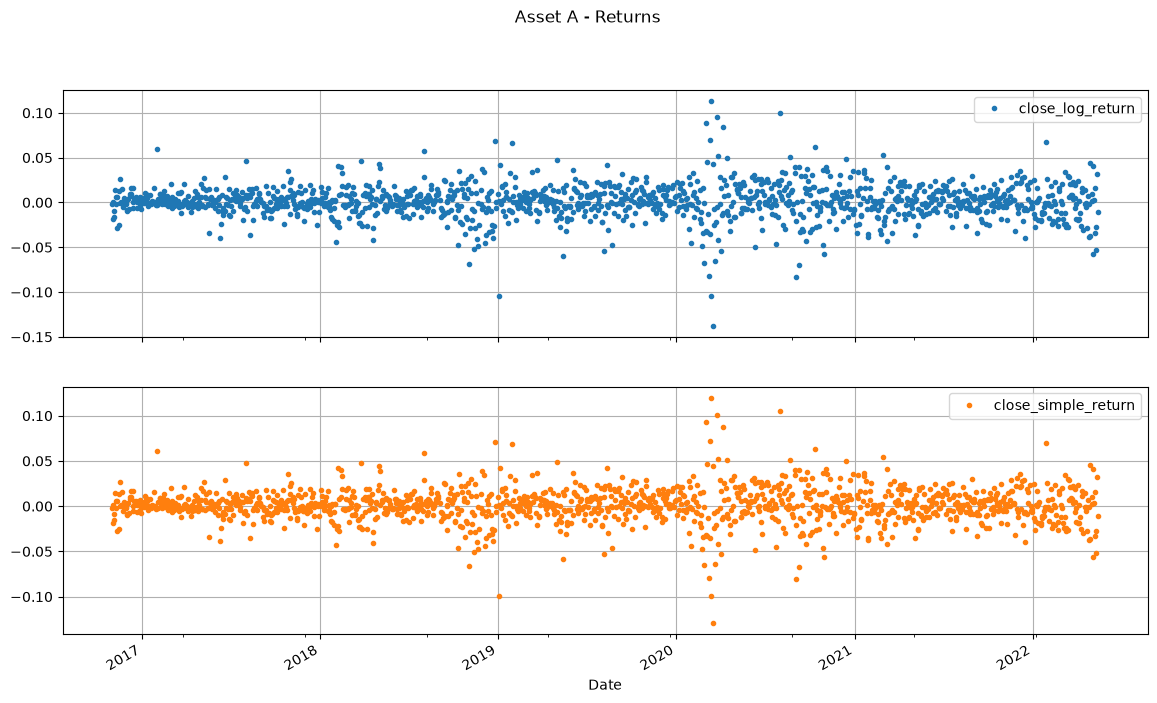

In [49]:
training_data['close_log_return'] = np.log(training_data['Close/Last']/training_data['Close/Last'].shift(1))
training_data['close_simple_return'] = training_data['Close/Last'].pct_change()
display(training_data.loc[:, :'close_simple_return'])

training_data.plot(x='Date', y=['close_log_return', 'close_simple_return'], subplots=True, layout=(2, 1), figsize=(14, 8), grid = True, style = 'o', ms = 3,title="Asset A - Returns")

# Strategy 1 Hypothesis

Yesterday's close-to-close return predicts a reversal during today's trading session. Following a negative return, today's open-to-close return is expected to be positive; following a positive return, it is expected to be negative. Trading against yesterday's direction is expected to generate positive average returns after costs.

For trading day $t$, the signal is yesterday's close-to-close log return:

$$
r_{t-1} = \ln\left(\frac{C_{t-1}}{C_{t-2}}\right)
$$

- **Long** if $r_{t-1} < 0$.
- **Short** if $r_{t-1} > 0$.
- **No trade** if $r_{t-1} = 0$ or the signal is unavailable.
- **Entry:** today's opening execution price.
- **Exit:** today's closing execution price.
- **Holding period:** intraday, with no overnight position.

With $s_t = +1$ for long, $-1$ for short, and $0$ for no position, the gross strategy return at 1x notional exposure is:

$$
R_t^{\mathrm{gross}} = s_t\left(\frac{C_t}{O_t} - 1\right)
$$

Net returns subtract entry costs, exit costs, and applicable shorting costs. Log returns generate the signal; simple returns measure strategy performance.

This hypothesis tests **intraday reversal**. Any reversal between yesterday's close and today's open occurs before entry and is not captured. Recorded opening and closing prices are initial execution benchmarks; the backtest must account for slippage and the feasibility of executing at those prices.


In [50]:
# Independent working data for Strategy 1.
# Add Strategy 1 signals and returns here without changing training_data.
strategy_1_data = training_data.copy(deep=True)
strategy_1_data = strategy_1_data.sort_values("Date")

strategy_1_data["Open"] = pd.to_numeric(strategy_1_data["Open"].astype(str).str.replace(r"[$,]", "", regex=True))

# Create lag close-close returns
strategy_1_data["lag_log_return"] = strategy_1_data["close_log_return"].shift(1)

# Find daily open-close simple returns
strategy_1_data["intraday_return"] = (strategy_1_data["Close/Last"] / strategy_1_data["Open"]) - 1

strategy_1_data = strategy_1_data.dropna(
    subset=["lag_log_return", "intraday_return"]
)

strategy_1_data["yesterday"] = np.select(
    [
        strategy_1_data["lag_log_return"] < 0,
        strategy_1_data["lag_log_return"] > 0,
    ],
    ["Down", "Up"],
    default="Unchanged",
)

summary = strategy_1_data.groupby("yesterday")["intraday_return"].agg(
    observations="count",
    mean_return="mean",
    median_return="median",
    volatility="std",
)

# Basis points make small average returns easier to read.
summary["mean_return_bp"] = summary["mean_return"] * 10_000
display(summary)

,observations,mean_return,median_return,volatility,mean_return_bp
yesterday,,,,,
Down,642,0.001477,0.002058,0.014824,14.774095
Unchanged,3,0.004291,0.003813,0.005891,42.907624
Up,749,0.000390,0.000311,0.013447,3.895100


## Strategy 1: confidence intervals for intraday reversal

Estimate uncertainty about three quantities: today's mean open-to-close return after a down day, the mean after an up day, and the difference (after-down minus after-up).

A **moving-block bootstrap** resamples consecutive chunks of chronological daily records. Each record keeps yesterday's signal paired with today's outcome. This retains some short-term dependence instead of treating days as independent. It does not recreate a synthetic price history or validate the signal-generation code.

Use training data only. The primary specification is **10-session blocks, 10,000 resamples, seed 42**. The intervals below are percentile, two-sided, individual 95% intervals in basis points (1 bp = 0.01%). They describe uncertainty in average returns, not a prediction interval for tomorrow. Their accuracy depends on dependence and stability assumptions.

Method reference: [Kunsch (1989), The Jackknife and the Bootstrap for General Stationary Observations](https://doi.org/10.1214/aos/1176347265).


In [51]:
# Keep chronological paired observations without modifying the strategy dataframe.
s1_ci_data = strategy_1_data.sort_values("Date")[[
    "Date", "lag_log_return", "intraday_return"
]].copy()

if s1_ci_data["Date"].duplicated().any():
    raise ValueError("Duplicate sessions must be resolved before bootstrapping.")
if not np.isfinite(s1_ci_data[["lag_log_return", "intraday_return"]].to_numpy()).all():
    raise ValueError("Resolve missing or non-finite signals/returns before bootstrapping.")

s1_signal = s1_ci_data["lag_log_return"].to_numpy()
s1_outcome = s1_ci_data["intraday_return"].to_numpy()
if (s1_signal < 0).sum() < 2 or (s1_signal > 0).sum() < 2:
    raise ValueError("Both signal groups need at least two observations.")


def s1_conditional_means(indices):
    signal = s1_signal[indices]
    outcome = s1_outcome[indices]
    after_down = outcome[signal < 0]
    after_up = outcome[signal > 0]
    if len(after_down) == 0 or len(after_up) == 0:
        return [np.nan, np.nan, np.nan]
    down_mean = after_down.mean()
    up_mean = after_up.mean()
    return [down_mean, up_mean, down_mean - up_mean]


def s1_bootstrap_intervals(block_length=10, n_resamples=10_000, seed=42):
    n = len(s1_ci_data)
    if not 1 <= block_length < n:
        raise ValueError("Block length must be positive and smaller than the sample.")
    rng = np.random.default_rng(seed)
    n_blocks = int(np.ceil(n / block_length))
    draws = np.empty((n_resamples, 3))

    for i in range(n_resamples):
        starts = rng.integers(0, n - block_length + 1, size=n_blocks)
        indices = (starts[:, None] + np.arange(block_length)).ravel()[:n]
        draws[i] = s1_conditional_means(indices)

    # Do not silently discard resamples with missing signal groups.
    if not np.isfinite(draws).all():
        raise ValueError("Some bootstrap samples lack a signal group; review sample adequacy.")
    bounds = np.quantile(draws, [0.025, 0.975], axis=0)
    return pd.DataFrame(
        {
            "mean_bp": np.array(s1_conditional_means(np.arange(n))) * 10_000,
            "lower_95_bp": bounds[0] * 10_000,
            "upper_95_bp": bounds[1] * 10_000,
        },
        index=pd.Index(["After down", "After up", "Down minus up"], name="quantity"),
    )


s1_confidence_intervals = s1_bootstrap_intervals()
display(s1_confidence_intervals.round(2))


,mean_bp,lower_95_bp,upper_95_bp
quantity,,,
After down,14.77,4.57,26.08
After up,3.90,-6.30,14.29
Down minus up,10.88,-4.66,26.68


### Interpretation of the primary training result

For the current training file, the 10-session block-bootstrap estimates are approximately:

| Quantity | Mean (bp) | Lower 95% bound (bp) | Upper 95% bound (bp) |
|---|---:|---:|---:|
| After down | 14.77 | 4.40 | 26.01 |
| After up | 3.90 | -6.25 | 14.33 |
| Down minus up | 10.88 | -4.71 | 26.72 |

- **After down:** the interval is entirely positive. This is preliminary evidence of positive average intraday returns after down days, before costs. It does not establish that buying after down days improves on general positive intraday drift.
- **After up:** the interval spans negative and positive values. A negative expected intraday return, as required by the short-side hypothesis, is not established. The positive sample mean implies a gross loss for that short leg in this training sample.
- **Down minus up:** the interval includes zero, so the estimated difference is uncertain. The table does not clearly establish that after-down returns exceed after-up returns.

**Conclusion:** the original two-sided reversal hypothesis is not clearly supported by this analysis. Positive after-down returns alone do not establish a reversal edge. Failure to exclude zero is inconclusive, not proof that an effect is absent.

These are approximate individual intervals, without a multiple-comparison adjustment or a formal one-sided p-value. They do not establish net profitability or out-of-sample persistence. If data or settings change, regenerate this written interpretation from the new output.


### Block-length sensitivity

Repeat the same analysis with 5- and 20-session blocks, retaining the 10-session result as the primary specification. Report all three; do not select whichever interval looks most favorable. Similar results across these settings improve confidence in robustness to this particular choice, but do not remove the need for costs, stability checks, and frozen held-out validation.


In [ ]:
s1_sensitivity = pd.concat(
    {
        5: s1_bootstrap_intervals(block_length=5),
        10: s1_confidence_intervals,
        20: s1_bootstrap_intervals(block_length=20),
    },
    names=["block_sessions", "quantity"],
)
display(s1_sensitivity.round(2))


### Strategy 1: findings and conclusion

The moving-block bootstrap results are consistent across the 5-, 10-, and 20-session block lengths:

- **After an up day:** today's average open-to-close return is approximately **+3.90 basis points**. Every confidence interval spans both negative and positive values. The analysis therefore does not establish the negative expected intraday return required by the short-side hypothesis. At the observed sample mean, shorting these sessions loses approximately 3.90 basis points per trade before costs.
- **After a down day:** today's average open-to-close return is approximately **+14.77 basis points**, and all three individual confidence intervals are entirely positive. This provides preliminary evidence of positive average intraday returns after down days, before costs. It does not by itself establish a reversal advantage over the asset's general positive intraday drift.
- **After-down minus after-up:** the estimated difference is approximately **+10.88 basis points**, but all three confidence intervals include zero. The analysis does not clearly establish that the two conditional means differ.

**Conclusion:** the short-side reversal hypothesis is not supported by this training sample, and the original combined long/short reversal hypothesis is not clearly established. This is not proof that reversal does not exist; the confidence intervals leave uncertainty about the underlying effects.

The three block lengths are sensitivity checks on the **same observations**, not three independent confirmations. Their agreement shows that the interpretation is stable across these particular block-length choices. These are approximate individual 95% intervals without a multiple-comparison adjustment. The findings are in-sample, before trading costs, and do not establish executable net profitability or out-of-sample persistence.


## Strategy 1: simple training backtest

Trade against yesterday's close-to-close log return: long after a down day, short after an up day, and flat after an unchanged day. Enter at today's recorded open and fully exit at today's recorded close. Use only the eligible **training** sessions in `strategy_1_data`.

Assumptions: **$10,000 starting capital**, fractional shares, and **1x start-of-session equity as entry notional**, resized daily. Gross and cost-scenario portfolios compound independently. Shorts use signed share P&L; short-sale proceeds are not additional capital.

The second portfolio subtracts **10 bp round-trip cost per active day: 5 bp to enter + 5 bp to exit** from return on entry equity. Both charges are calculated on entry notional in this fixed-round-trip model. Change the entry and exit parameters below to explore another scenario. This combines assumed trading frictions into one charge; it is not an evidenced estimate of attainable fees, spread, slippage, or borrow costs. Every active session incurs a round trip even if tomorrow's side is unchanged.

Recorded open/close prices are benchmark fills. Short availability, margin constraints, auction participation, actual fills, taxes, financing, and interest on idle cash are not modeled. This is an in-sample illustration, not a validated executable strategy. Market execution prices are not guaranteed: [SEC order-type guidance](https://www.sec.gov/investor/alerts/trading101basics.pdf).


In [6]:
# Configurable assumptions.
s1_initial_capital = 10_000.0
s1_entry_cost_bps = 5.0
s1_exit_cost_bps = 5.0
s1_round_trip_cost_bps = s1_entry_cost_bps + s1_exit_cost_bps  # 10 bp total.

if not np.isfinite(s1_initial_capital) or s1_initial_capital <= 0:
    raise ValueError("Starting capital must be positive and finite.")
if not np.isfinite([s1_entry_cost_bps, s1_exit_cost_bps]).all() or min(s1_entry_cost_bps, s1_exit_cost_bps) < 0:
    raise ValueError("Trading cost must be nonnegative and finite.")

s1_backtest = strategy_1_data.sort_values("Date").copy()
if s1_backtest.empty or s1_backtest["Date"].duplicated().any():
    raise ValueError("Backtest needs nonempty data with unique session dates.")
if not np.isfinite(s1_backtest[["Open", "Close/Last", "lag_log_return"]].to_numpy()).all():
    raise ValueError("Backtest inputs must be finite with valid signal history.")
if (s1_backtest[["Open", "Close/Last"]] <= 0).any().any():
    raise ValueError("Execution benchmark prices must be positive.")

s1_backtest["position"] = -np.sign(s1_backtest["lag_log_return"]).astype(int)
s1_backtest["side"] = s1_backtest["position"].map({1: "Long", -1: "Short", 0: "Flat"})
s1_backtest["asset_intraday_return"] = s1_backtest["Close/Last"] / s1_backtest["Open"] - 1
s1_backtest["gross_return"] = s1_backtest["position"] * s1_backtest["asset_intraday_return"]
s1_backtest["entry_cost_return"] = s1_backtest["position"].abs() * s1_entry_cost_bps / 10_000
s1_backtest["exit_cost_return"] = s1_backtest["position"].abs() * s1_exit_cost_bps / 10_000
s1_backtest["cost_return"] = s1_backtest["entry_cost_return"] + s1_backtest["exit_cost_return"]
s1_backtest.attrs["entry_cost_bps"] = s1_entry_cost_bps
s1_backtest.attrs["exit_cost_bps"] = s1_exit_cost_bps
s1_backtest["net_return"] = s1_backtest["gross_return"] - s1_backtest["cost_return"]

if (s1_backtest[["gross_return", "net_return"]] <= -1).any().any():
    raise ValueError("A daily return exhausts capital; this simple model cannot continue.")

s1_backtest["gross_equity"] = s1_initial_capital * (1 + s1_backtest["gross_return"]).cumprod()
s1_backtest["net_equity"] = s1_initial_capital * (1 + s1_backtest["net_return"]).cumprod()
s1_backtest["gross_start_equity"] = s1_backtest["gross_equity"].shift(1, fill_value=s1_initial_capital)
s1_backtest["net_start_equity"] = s1_backtest["net_equity"].shift(1, fill_value=s1_initial_capital)
s1_backtest["gross_pnl"] = s1_backtest["gross_start_equity"] * s1_backtest["gross_return"]
s1_backtest["entry_cost_dollars"] = s1_backtest["net_start_equity"] * s1_backtest["entry_cost_return"]
s1_backtest["exit_cost_dollars"] = s1_backtest["net_start_equity"] * s1_backtest["exit_cost_return"]
s1_backtest["cost_dollars"] = s1_backtest["entry_cost_dollars"] + s1_backtest["exit_cost_dollars"]
s1_backtest["net_pnl"] = s1_backtest["net_start_equity"] * s1_backtest["net_return"]
s1_backtest["net_shares"] = s1_backtest["position"] * s1_backtest["net_start_equity"] / s1_backtest["Open"]

# Include initial capital in the high-water mark, even if the first trade loses.
for portfolio in ["gross", "net"]:
    peak = s1_backtest[f"{portfolio}_equity"].cummax().clip(lower=s1_initial_capital)
    s1_backtest[f"{portfolio}_drawdown"] = s1_backtest[f"{portfolio}_equity"] / peak - 1

def s1_annualized_sharpe(daily_returns, periods_per_year=252, annual_risk_free_rate=0.0):
    """Conventional annualized Sharpe using all eligible sessions, including cash days."""
    daily_risk_free = (1 + annual_risk_free_rate) ** (1 / periods_per_year) - 1
    excess_returns = daily_returns - daily_risk_free
    volatility = excess_returns.std(ddof=1)
    if not np.isfinite(volatility) or volatility <= 0:
        return np.nan
    return np.sqrt(periods_per_year) * excess_returns.mean() / volatility


s1_active = s1_backtest["position"].ne(0)
s1_cost_label = (
    f"Net ({s1_round_trip_cost_bps:g} bp round trip: "
    f"{s1_entry_cost_bps:g} bp entry + {s1_exit_cost_bps:g} bp exit)"
)
s1_backtest_summary = pd.DataFrame({
    label: {
        "Entry cost (bp)": s1_entry_cost_bps if portfolio == "net" else 0.0,
        "Exit cost (bp)": s1_exit_cost_bps if portfolio == "net" else 0.0,
        "Round-trip cost (bp)": s1_round_trip_cost_bps if portfolio == "net" else 0.0,
        "Starting capital ($)": s1_initial_capital,
        "Ending equity ($)": s1_backtest[f"{portfolio}_equity"].iloc[-1],
        "Total P&L ($)": s1_backtest[f"{portfolio}_pnl"].sum(),
        "Total return (%)": (s1_backtest[f"{portfolio}_equity"].iloc[-1] / s1_initial_capital - 1) * 100,
        "Maximum drawdown (%)": s1_backtest[f"{portfolio}_drawdown"].min() * 100,
        "Annualized Sharpe (rf=0%)": s1_annualized_sharpe(s1_backtest[f"{portfolio}_return"]),
        "Mean return per active trade (bp)": s1_backtest.loc[s1_active, f"{portfolio}_return"].mean() * 10_000,
        "Winning trades (%)": s1_backtest.loc[s1_active, f"{portfolio}_pnl"].gt(0).mean() * 100,
        "Active trades": int(s1_active.sum()),
    }
    for portfolio, label in [("gross", "Gross"), ("net", s1_cost_label)]
})
display(s1_backtest_summary.round(2))

s1_side_summary = s1_backtest.groupby("side").agg(
    sessions=("Date", "size"),
    gross_pnl_dollars=("gross_pnl", "sum"),
    net_pnl_dollars=("net_pnl", "sum"),
    entry_cost_dollars=("entry_cost_dollars", "sum"),
    exit_cost_dollars=("exit_cost_dollars", "sum"),
    total_cost_dollars=("cost_dollars", "sum"),
)
s1_side_summary.columns.name = s1_cost_label
display(s1_side_summary.round(2))
display(s1_backtest[[
    "Date", "lag_log_return", "side", "Open", "Close/Last", "net_shares",
    "gross_return", "entry_cost_return", "exit_cost_return", "cost_return",
    "entry_cost_dollars", "exit_cost_dollars", "cost_dollars", "net_return", "net_pnl", "net_equity"
]].head(10))


,Gross,Net (10 bp round trip: 5 bp entry + 5 bp exit)
Entry cost (bp),0.00,5.00
Exit cost (bp),0.00,5.00
Round-trip cost (bp),0.00,10.00
Starting capital ($),10000.00,10000.00
Ending equity ($),16791.91,4176.95
Total P&L ($),6791.91,-5823.05
Total return (%),67.92,-58.23
Maximum drawdown (%),-34.57,-70.15
Annualized Sharpe (rf=0%),0.53,-0.59
Mean return per active trade (bp),4.72,-5.28


Net (10 bp round trip: 5 bp entry + 5 bp exit),sessions,gross_pnl_dollars,net_pnl_dollars,entry_cost_dollars,exit_cost_dollars,total_cost_dollars
side,,,,,,
Flat,3,0.00,0.00,0.00,0.00,0.00
Long,642,9557.57,639.35,1780.27,1780.27,3560.54
Short,749,-2765.66,-6462.40,2086.58,2086.58,4173.15


,Date,lag_log_return,side,Open,Close/Last,net_shares,gross_return,entry_cost_return,exit_cost_return,cost_return,entry_cost_dollars,exit_cost_dollars,cost_dollars,net_return,net_pnl,net_equity
2,2016-11-01,-0.001584,Long,28.3650,27.8725,352.547153,-0.017363,0.0005,0.0005,0.001,5.000000,5.000000,10.000000,-0.018363,-183.629473,9816.370527
3,2016-11-02,-0.018220,Long,27.8500,27.8975,352.472909,0.001706,0.0005,0.0005,0.001,4.908185,4.908185,9.816371,0.000706,6.926093,9823.296620
4,2016-11-03,0.000897,Short,27.7450,27.4575,-354.056465,0.010362,0.0005,0.0005,0.001,4.911648,4.911648,9.823297,0.009362,91.967937,9915.264557
5,2016-11-04,-0.015898,Long,27.1325,27.2100,365.438664,0.002856,0.0005,0.0005,0.001,4.957632,4.957632,9.915265,0.001856,18.406232,9933.670789
6,2016-11-07,-0.009055,Long,27.5200,27.6025,360.961875,0.002998,0.0005,0.0005,0.001,4.966835,4.966835,9.933671,0.001998,19.845684,9953.516473
7,2016-11-08,0.014322,Short,27.5775,27.7650,-360.928890,-0.006799,0.0005,0.0005,0.001,4.976758,4.976758,9.953516,-0.007799,-77.627683,9875.888789
8,2016-11-09,0.005870,Short,27.4700,27.7200,-359.515427,-0.009101,0.0005,0.0005,0.001,4.937944,4.937944,9.875889,-0.010101,-99.754746,9776.134044
9,2016-11-10,-0.001622,Long,27.7725,26.9475,352.007707,-0.029706,0.0005,0.0005,0.001,4.888067,4.888067,9.776134,-0.030706,-300.182492,9475.951551
10,2016-11-11,-0.028264,Long,26.7800,27.1075,353.844345,0.012229,0.0005,0.0005,0.001,4.737976,4.737976,9.475952,0.011229,106.408071,9582.359623
11,2016-11-14,0.005920,Short,26.9275,26.4275,-355.857752,0.018568,0.0005,0.0005,0.001,4.791180,4.791180,9.582360,0.017568,168.346516,9750.706139


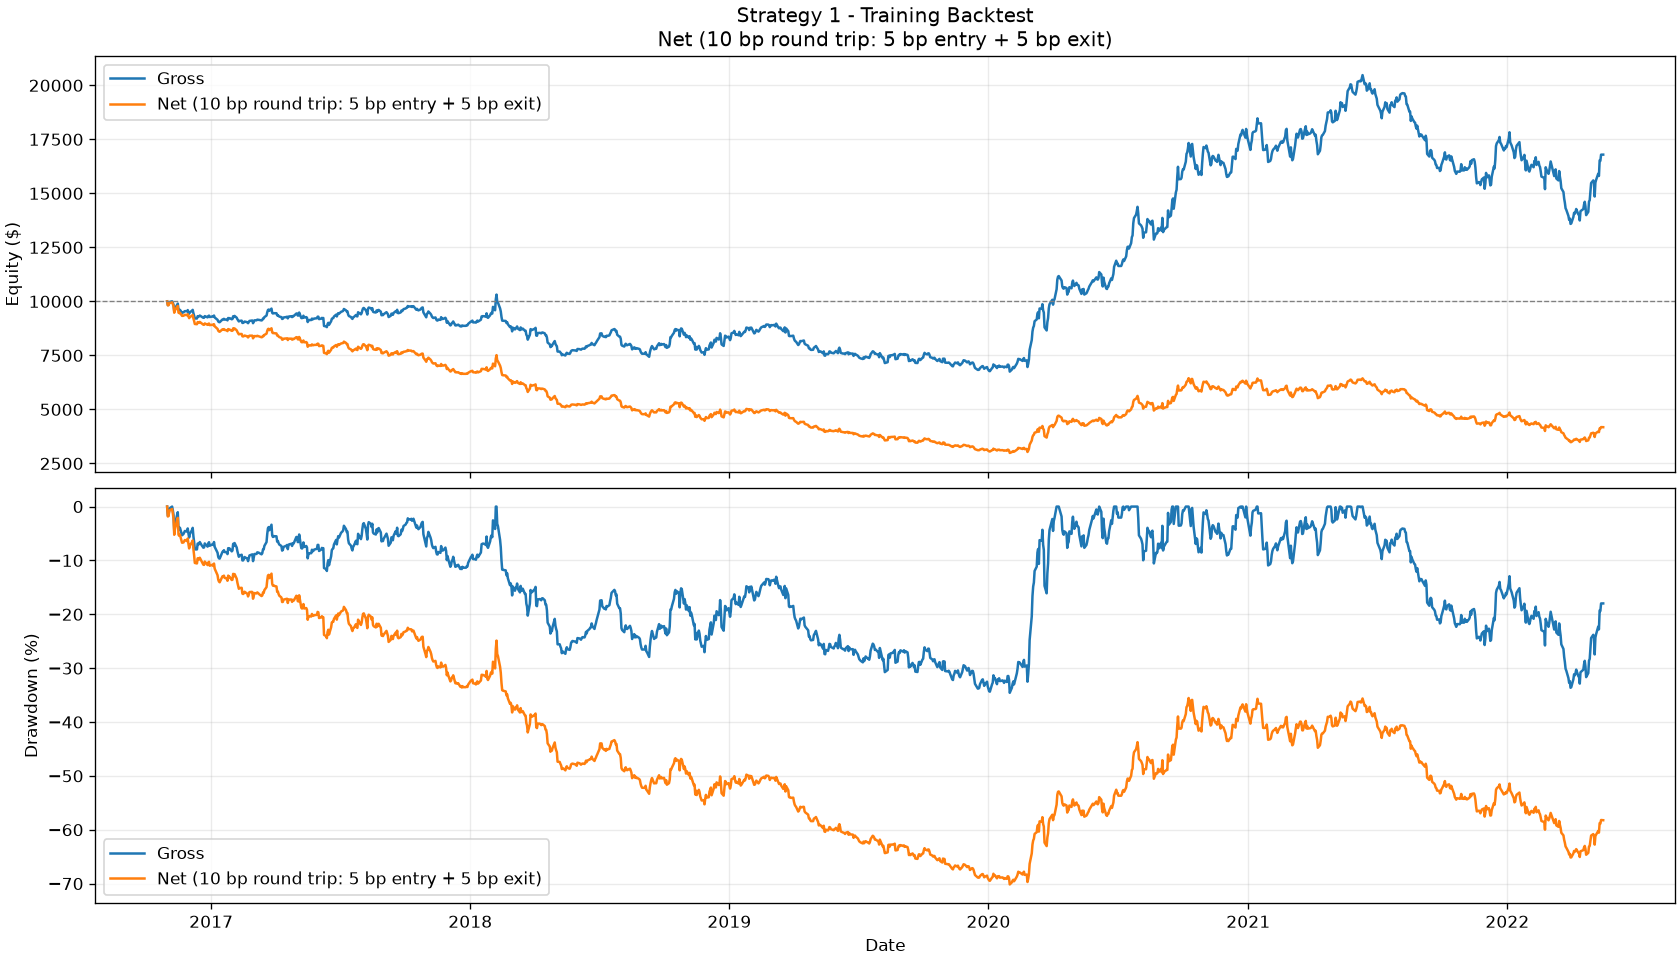

In [7]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Derive the label from the cost settings used to calculate this ledger.
s1_chart_entry_bps = s1_backtest.attrs["entry_cost_bps"]
s1_chart_exit_bps = s1_backtest.attrs["exit_cost_bps"]
s1_chart_cost_label = (
    f"Net ({s1_chart_entry_bps + s1_chart_exit_bps:g} bp round trip: "
    f"{s1_chart_entry_bps:g} bp entry + {s1_chart_exit_bps:g} bp exit)"
)

# Start the chart at initial capital on the preceding training session.
s1_first_trade_date = s1_backtest["Date"].iloc[0]
s1_previous_sessions = training_data.loc[training_data["Date"] < s1_first_trade_date, "Date"]
s1_baseline_date = (
    s1_previous_sessions.iloc[-1] if len(s1_previous_sessions)
    else s1_first_trade_date - pd.Timedelta(days=1)
)
s1_chart = s1_backtest.set_index("Date")[[
    "gross_equity", "net_equity", "gross_drawdown", "net_drawdown"
]]
s1_chart = pd.concat([
    pd.DataFrame({
        "gross_equity": [s1_initial_capital], "net_equity": [s1_initial_capital],
        "gross_drawdown": [0.0], "net_drawdown": [0.0],
    }, index=pd.DatetimeIndex([s1_baseline_date], name="Date")),
    s1_chart,
])

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True, layout="constrained")
axes[0].plot(s1_chart.index, s1_chart["gross_equity"], label="Gross", color="tab:blue")
axes[0].plot(s1_chart.index, s1_chart["net_equity"], label=s1_chart_cost_label, color="tab:orange")
axes[0].axhline(s1_initial_capital, color="gray", linestyle="--", linewidth=0.8)
axes[0].set(title=f"Strategy 1 - Training Backtest\n{s1_chart_cost_label}", ylabel="Equity ($)")
axes[1].plot(s1_chart.index, s1_chart["gross_drawdown"] * 100, label="Gross", color="tab:blue")
axes[1].plot(s1_chart.index, s1_chart["net_drawdown"] * 100, label=s1_chart_cost_label, color="tab:orange")
axes[1].set(xlabel="Date", ylabel="Drawdown (%)")
for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend()
locator = mdates.AutoDateLocator(minticks=6, maxticks=12)
axes[1].xaxis.set_major_locator(locator)
axes[1].xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
plt.show()


### Original long/short backtest: findings

Training window: **2016-11-01 to 2022-05-16**, with **1,394 eligible sessions**. Starting capital is **$10,000**, with 1x entry-equity position sizing and daily compounding. Costs are **5 bp to enter + 5 bp to exit = 10 bp per active round trip**, both charged on entry notional.

| Statistic | Before costs | After costs |
|---|---:|---:|
| Ending equity | $16,791.91 | $4,176.95 |
| Total P&L | $+6,791.91 | $-5,823.05 |
| Total return | +67.92% | -58.23% |
| Maximum drawdown from a prior equity peak | -34.57% | -70.15% |
| Annualized Sharpe ratio (0% risk-free rate) | 0.53 | -0.59 |
| Average return per active trade | +4.72 bp | -5.28 bp |
| Winning trades | 52.55% | 48.45% |

**Sharpe convention:** sqrt(252) x mean daily excess return / sample standard deviation of daily excess returns, assuming a zero risk-free rate. All eligible sessions are included, including zero-return cash days. This is conventional descriptive annualization, not an adjustment for serial dependence or proof of statistical significance.

**Activity:** 1,391 trades: 642 long, 749 short, and 3 flat sessions. Total modeled charges paid by the net portfolio are **$7,733.70**. These charges are not the same as the gross-minus-net ending-equity gap because costs also alter subsequent position sizes and compounding.

**Findings:** the strategy makes money before costs but loses money after the assumed 10 bp round-trip charge. Its average gross gain of 4.72 bp per trade is smaller than the charge, leaving an average net loss of 5.28 bp per trade. The short leg averages a 3.90 bp gross loss per trade even before costs. The 70.15% net maximum drawdown indicates a substantial peak-to-trough loss.

**Conclusion:** the original long/short rule is not profitable in this training backtest under the stated cost assumptions. Gross profits do not establish an executable edge. This is an in-sample benchmark-fill simulation, not a validation of actual execution or future performance.


## Strategy 1 variant: long-only training backtest

**Rule:** buy at today's open only when yesterday's close-to-close log return is negative, and sell at today's close. Stay in cash after up or unchanged days. Flat days have zero return and no transaction charge; there is no overnight position.

Use the same eligible training sessions, $10,000 starting capital, 1x start-of-session equity sizing, fractional shares, and independent daily compounding as the original backtest. Costs remain **5 bp entry + 5 bp exit = 10 bp round trip**, both charged on entry notional. The long-only portfolio is rebuilt from its own capital path; it is not the sum of the original portfolio's long-leg dollar profits.

This is a separate exploratory strategy variant, chosen after examining the same training data. Its results do not independently validate reversal. Execution, adjustment, financing, and cash-interest assumptions remain those of the original backtest; cash earns zero here. Testing and final unseen data remain unused.


In [8]:
# Configurable assumptions.
s1_long_initial_capital = 10_000.0
s1_long_entry_cost_bps = 5.0
s1_long_exit_cost_bps = 5.0
s1_long_round_trip_cost_bps = s1_long_entry_cost_bps + s1_long_exit_cost_bps  # 10 bp total.

if not np.isfinite(s1_long_initial_capital) or s1_long_initial_capital <= 0:
    raise ValueError("Starting capital must be positive and finite.")
if not np.isfinite([s1_long_entry_cost_bps, s1_long_exit_cost_bps]).all() or min(s1_long_entry_cost_bps, s1_long_exit_cost_bps) < 0:
    raise ValueError("Trading cost must be nonnegative and finite.")

s1_long_backtest = strategy_1_data.sort_values("Date").copy()
if s1_long_backtest.empty or s1_long_backtest["Date"].duplicated().any():
    raise ValueError("Backtest needs nonempty data with unique session dates.")
if not np.isfinite(s1_long_backtest[["Open", "Close/Last", "lag_log_return"]].to_numpy()).all():
    raise ValueError("Backtest inputs must be finite with valid signal history.")
if (s1_long_backtest[["Open", "Close/Last"]] <= 0).any().any():
    raise ValueError("Execution benchmark prices must be positive.")

s1_long_backtest["position"] = s1_long_backtest["lag_log_return"].lt(0).astype(int)
s1_long_backtest["side"] = s1_long_backtest["position"].map({1: "Long", 0: "Flat"})
s1_long_backtest["asset_intraday_return"] = s1_long_backtest["Close/Last"] / s1_long_backtest["Open"] - 1
s1_long_backtest["gross_return"] = s1_long_backtest["position"] * s1_long_backtest["asset_intraday_return"]
s1_long_backtest["entry_cost_return"] = s1_long_backtest["position"].abs() * s1_long_entry_cost_bps / 10_000
s1_long_backtest["exit_cost_return"] = s1_long_backtest["position"].abs() * s1_long_exit_cost_bps / 10_000
s1_long_backtest["cost_return"] = s1_long_backtest["entry_cost_return"] + s1_long_backtest["exit_cost_return"]
s1_long_backtest.attrs["entry_cost_bps"] = s1_long_entry_cost_bps
s1_long_backtest.attrs["exit_cost_bps"] = s1_long_exit_cost_bps
s1_long_backtest["net_return"] = s1_long_backtest["gross_return"] - s1_long_backtest["cost_return"]

if (s1_long_backtest[["gross_return", "net_return"]] <= -1).any().any():
    raise ValueError("A daily return exhausts capital; this simple model cannot continue.")

s1_long_backtest["gross_equity"] = s1_long_initial_capital * (1 + s1_long_backtest["gross_return"]).cumprod()
s1_long_backtest["net_equity"] = s1_long_initial_capital * (1 + s1_long_backtest["net_return"]).cumprod()
s1_long_backtest["gross_start_equity"] = s1_long_backtest["gross_equity"].shift(1, fill_value=s1_long_initial_capital)
s1_long_backtest["net_start_equity"] = s1_long_backtest["net_equity"].shift(1, fill_value=s1_long_initial_capital)
s1_long_backtest["gross_pnl"] = s1_long_backtest["gross_start_equity"] * s1_long_backtest["gross_return"]
s1_long_backtest["entry_cost_dollars"] = s1_long_backtest["net_start_equity"] * s1_long_backtest["entry_cost_return"]
s1_long_backtest["exit_cost_dollars"] = s1_long_backtest["net_start_equity"] * s1_long_backtest["exit_cost_return"]
s1_long_backtest["cost_dollars"] = s1_long_backtest["entry_cost_dollars"] + s1_long_backtest["exit_cost_dollars"]
s1_long_backtest["net_pnl"] = s1_long_backtest["net_start_equity"] * s1_long_backtest["net_return"]
s1_long_backtest["net_shares"] = s1_long_backtest["position"] * s1_long_backtest["net_start_equity"] / s1_long_backtest["Open"]

# Include initial capital in the high-water mark, even if the first trade loses.
for portfolio in ["gross", "net"]:
    peak = s1_long_backtest[f"{portfolio}_equity"].cummax().clip(lower=s1_long_initial_capital)
    s1_long_backtest[f"{portfolio}_drawdown"] = s1_long_backtest[f"{portfolio}_equity"] / peak - 1

s1_long_active = s1_long_backtest["position"].ne(0)
s1_long_cost_label = (
    f"Net long-only ({s1_long_round_trip_cost_bps:g} bp round trip: "
    f"{s1_long_entry_cost_bps:g} bp entry + {s1_long_exit_cost_bps:g} bp exit)"
)
s1_long_backtest_summary = pd.DataFrame({
    label: {
        "Entry cost (bp)": s1_long_entry_cost_bps if portfolio == "net" else 0.0,
        "Exit cost (bp)": s1_long_exit_cost_bps if portfolio == "net" else 0.0,
        "Round-trip cost (bp)": s1_long_round_trip_cost_bps if portfolio == "net" else 0.0,
        "Starting capital ($)": s1_long_initial_capital,
        "Ending equity ($)": s1_long_backtest[f"{portfolio}_equity"].iloc[-1],
        "Total P&L ($)": s1_long_backtest[f"{portfolio}_pnl"].sum(),
        "Total return (%)": (s1_long_backtest[f"{portfolio}_equity"].iloc[-1] / s1_long_initial_capital - 1) * 100,
        "Maximum drawdown (%)": s1_long_backtest[f"{portfolio}_drawdown"].min() * 100,
        "Annualized Sharpe (rf=0%)": s1_annualized_sharpe(s1_long_backtest[f"{portfolio}_return"]),
        "Mean return per active trade (bp)": s1_long_backtest.loc[s1_long_active, f"{portfolio}_return"].mean() * 10_000,
        "Winning trades (%)": s1_long_backtest.loc[s1_long_active, f"{portfolio}_pnl"].gt(0).mean() * 100,
        "Active trades": int(s1_long_active.sum()),
    }
    for portfolio, label in [("gross", "Gross long-only"), ("net", s1_long_cost_label)]
})
display(s1_long_backtest_summary.round(2))

s1_long_side_summary = s1_long_backtest.groupby("side").agg(
    sessions=("Date", "size"),
    gross_pnl_dollars=("gross_pnl", "sum"),
    net_pnl_dollars=("net_pnl", "sum"),
    entry_cost_dollars=("entry_cost_dollars", "sum"),
    exit_cost_dollars=("exit_cost_dollars", "sum"),
    total_cost_dollars=("cost_dollars", "sum"),
)
s1_long_side_summary.columns.name = s1_long_cost_label
display(s1_long_side_summary.round(2))
display(s1_long_backtest[[
    "Date", "lag_log_return", "side", "Open", "Close/Last", "net_shares",
    "gross_return", "entry_cost_return", "exit_cost_return", "cost_return",
    "entry_cost_dollars", "exit_cost_dollars", "cost_dollars", "net_return", "net_pnl", "net_equity"
]].head(10))

# Compare independently compounded portfolios on exactly the same sessions.
s1_variant_comparison = pd.DataFrame({
    label: {
        "Active trades": int(bt["position"].ne(0).sum()),
        "Gross ending equity ($)": bt["gross_equity"].iloc[-1],
        "Net ending equity ($)": bt["net_equity"].iloc[-1],
        "Net P&L ($)": bt["net_pnl"].sum(),
        "Net return (%)": (bt["net_equity"].iloc[-1] / s1_initial_capital - 1) * 100,
        "Net maximum drawdown (%)": bt["net_drawdown"].min() * 100,
        "Gross annualized Sharpe (rf=0%)": s1_annualized_sharpe(bt["gross_return"]),
        "Net annualized Sharpe (rf=0%)": s1_annualized_sharpe(bt["net_return"]),
    }
    for label, bt in [("Original long/short - 10 bp round trip", s1_backtest),
                      ("Long-only - 10 bp round trip", s1_long_backtest)]
})
display(s1_variant_comparison.round(2))


,Gross long-only,Net long-only (10 bp round trip: 5 bp entry + 5 bp exit)
Entry cost (bp),0.00,5.00
Exit cost (bp),0.00,5.00
Round-trip cost (bp),0.00,10.00
Starting capital ($),10000.00,10000.00
Ending equity ($),24051.17,12662.82
Total P&L ($),14051.17,2662.82
Total return (%),140.51,26.63
Maximum drawdown (%),-16.30,-29.66
Annualized Sharpe (rf=0%),1.07,0.35
Mean return per active trade (bp),14.77,4.77


Net long-only (10 bp round trip: 5 bp entry + 5 bp exit),sessions,gross_pnl_dollars,net_pnl_dollars,entry_cost_dollars,exit_cost_dollars,total_cost_dollars
side,,,,,,
Flat,752,0.00,0.00,0.00,0.00,0.00
Long,642,14051.17,2662.82,3415.12,3415.12,6830.24


,Date,lag_log_return,side,Open,Close/Last,net_shares,gross_return,entry_cost_return,exit_cost_return,cost_return,entry_cost_dollars,exit_cost_dollars,cost_dollars,net_return,net_pnl,net_equity
2,2016-11-01,-0.001584,Long,28.3650,27.8725,352.547153,-0.017363,0.0005,0.0005,0.001,5.000000,5.000000,10.000000,-0.018363,-183.629473,9816.370527
3,2016-11-02,-0.018220,Long,27.8500,27.8975,352.472909,0.001706,0.0005,0.0005,0.001,4.908185,4.908185,9.816371,0.000706,6.926093,9823.296620
4,2016-11-03,0.000897,Flat,27.7450,27.4575,0.000000,-0.000000,0.0000,0.0000,0.000,0.000000,0.000000,0.000000,-0.000000,-0.000000,9823.296620
5,2016-11-04,-0.015898,Long,27.1325,27.2100,362.049078,0.002856,0.0005,0.0005,0.001,4.911648,4.911648,9.823297,0.001856,18.235507,9841.532127
6,2016-11-07,-0.009055,Long,27.5200,27.6025,357.613813,0.002998,0.0005,0.0005,0.001,4.920766,4.920766,9.841532,0.001998,19.661607,9861.193734
7,2016-11-08,0.014322,Flat,27.5775,27.7650,0.000000,0.000000,0.0000,0.0000,0.000,0.000000,0.000000,0.000000,0.000000,0.000000,9861.193734
8,2016-11-09,0.005870,Flat,27.4700,27.7200,0.000000,0.000000,0.0000,0.0000,0.000,0.000000,0.000000,0.000000,0.000000,0.000000,9861.193734
9,2016-11-10,-0.001622,Long,27.7725,26.9475,355.070438,-0.029706,0.0005,0.0005,0.001,4.930597,4.930597,9.861194,-0.030706,-302.794305,9558.399429
10,2016-11-11,-0.028264,Long,26.7800,27.1075,356.923056,0.012229,0.0005,0.0005,0.001,4.779200,4.779200,9.558399,0.011229,107.333901,9665.733330
11,2016-11-14,0.005920,Flat,26.9275,26.4275,0.000000,-0.000000,0.0000,0.0000,0.000,0.000000,0.000000,0.000000,-0.000000,-0.000000,9665.733330


,Original long/short - 10 bp round trip,Long-only - 10 bp round trip
Active trades,1391.00,642.00
Gross ending equity ($),16791.91,24051.17
Net ending equity ($),4176.95,12662.82
Net P&L ($),-5823.05,2662.82
Net return (%),-58.23,26.63
Net maximum drawdown (%),-70.15,-29.66
Gross annualized Sharpe (rf=0%),0.53,1.07
Net annualized Sharpe (rf=0%),-0.59,0.35


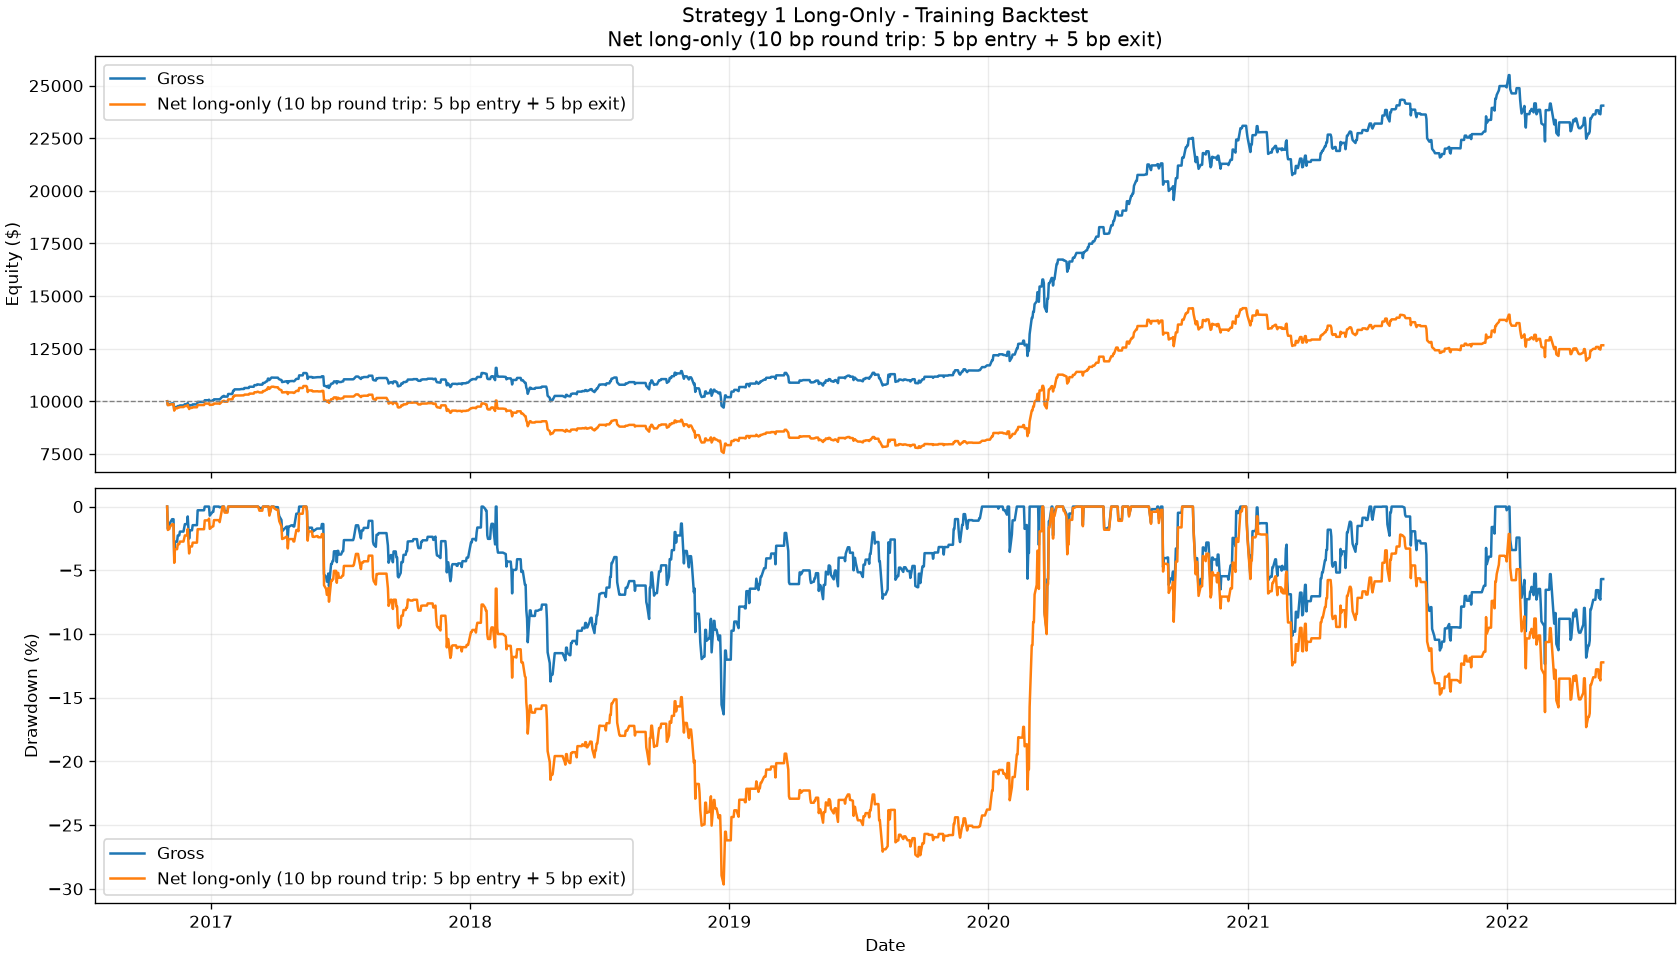

In [9]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# Derive the label from the cost settings used to calculate this ledger.
s1_long_chart_entry_bps = s1_long_backtest.attrs["entry_cost_bps"]
s1_long_chart_exit_bps = s1_long_backtest.attrs["exit_cost_bps"]
s1_long_chart_cost_label = (
    f"Net long-only ({s1_long_chart_entry_bps + s1_long_chart_exit_bps:g} bp round trip: "
    f"{s1_long_chart_entry_bps:g} bp entry + {s1_long_chart_exit_bps:g} bp exit)"
)

# Start the chart at initial capital on the preceding training session.
s1_long_first_trade_date = s1_long_backtest["Date"].iloc[0]
s1_long_previous_sessions = training_data.loc[training_data["Date"] < s1_long_first_trade_date, "Date"]
s1_long_baseline_date = (
    s1_long_previous_sessions.iloc[-1] if len(s1_long_previous_sessions)
    else s1_long_first_trade_date - pd.Timedelta(days=1)
)
s1_long_chart = s1_long_backtest.set_index("Date")[[
    "gross_equity", "net_equity", "gross_drawdown", "net_drawdown"
]]
s1_long_chart = pd.concat([
    pd.DataFrame({
        "gross_equity": [s1_long_initial_capital], "net_equity": [s1_long_initial_capital],
        "gross_drawdown": [0.0], "net_drawdown": [0.0],
    }, index=pd.DatetimeIndex([s1_long_baseline_date], name="Date")),
    s1_long_chart,
])

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True, layout="constrained")
axes[0].plot(s1_long_chart.index, s1_long_chart["gross_equity"], label="Gross", color="tab:blue")
axes[0].plot(s1_long_chart.index, s1_long_chart["net_equity"], label=s1_long_chart_cost_label, color="tab:orange")
axes[0].axhline(s1_long_initial_capital, color="gray", linestyle="--", linewidth=0.8)
axes[0].set(title=f"Strategy 1 Long-Only - Training Backtest\n{s1_long_chart_cost_label}", ylabel="Equity ($)")
axes[1].plot(s1_long_chart.index, s1_long_chart["gross_drawdown"] * 100, label="Gross", color="tab:blue")
axes[1].plot(s1_long_chart.index, s1_long_chart["net_drawdown"] * 100, label=s1_long_chart_cost_label, color="tab:orange")
axes[1].set(xlabel="Date", ylabel="Drawdown (%)")
for ax in axes:
    ax.grid(alpha=0.25)
    ax.legend()
locator = mdates.AutoDateLocator(minticks=6, maxticks=12)
axes[1].xaxis.set_major_locator(locator)
axes[1].xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
plt.show()


### Long-only backtest: findings

Training window: **2016-11-01 to 2022-05-16**, with **1,394 eligible sessions**. Starting capital is **$10,000**, with 1x entry-equity position sizing and daily compounding. Costs are **5 bp to enter + 5 bp to exit = 10 bp per active round trip**, both charged on entry notional.

| Statistic | Before costs | After costs |
|---|---:|---:|
| Ending equity | $24,051.17 | $12,662.82 |
| Total P&L | $+14,051.17 | $+2,662.82 |
| Total return | +140.51% | +26.63% |
| Maximum drawdown from a prior equity peak | -16.30% | -29.66% |
| Annualized Sharpe ratio (0% risk-free rate) | 1.07 | 0.35 |
| Average return per active trade | +14.77 bp | +4.77 bp |
| Winning trades | 56.54% | 53.74% |

**Sharpe convention:** sqrt(252) x mean daily excess return / sample standard deviation of daily excess returns, assuming a zero risk-free rate. All eligible sessions are included, including zero-return cash days. This is conventional descriptive annualization, not an adjustment for serial dependence or proof of statistical significance.

**Activity:** 642 trades: 642 long, 0 short, and 752 flat sessions. Total modeled charges paid by the net portfolio are **$6,830.24**. These charges are not the same as the gross-minus-net ending-equity gap because costs also alter subsequent position sizes and compounding.

**Findings:** buying only after down days produces a positive training result after costs. The average gross gain of 14.77 bp per trade exceeds the 10 bp round-trip charge, leaving 4.77 bp per active trade on average. It makes 749 fewer trades than the original rule by removing shorts. Net total return improves from -58.23% to 26.63%, while net maximum drawdown improves from -70.15% to -29.66%. The remaining drawdown is still substantial despite the positive ending P&L.

**Conclusion:** the long-only variant is more promising in this training sample, but it was selected after examining the original results. It does not independently establish reversal or outperformance versus always-long intraday exposure. Costs and benchmark-fill assumptions remain material; a frozen held-out evaluation is still needed. Its dollar profits follow its own compounded capital path and are not simply the long-leg P&L from the original portfolio.


## Strategy 2: four one-lag return forecasts

Test four small models together. **"Price movement" means simple percentage return**, not a dollar price level. Let $q_t=C_t/C_{t-1}-1$ be close-to-close return and $d_t=C_t/O_t-1$ be open-to-close return. Each model includes an intercept:

| Model | Today's target | Yesterday's predictor | Equation |
|---|---|---|---|
| OC from CC | Open-to-close | Close-to-close | $d_t=\alpha+\beta q_{t-1}+\epsilon_t$ |
| OC from OC | Open-to-close | Open-to-close | $d_t=\alpha+\beta d_{t-1}+\epsilon_t$ |
| CC from CC | Close-to-close | Close-to-close | $q_t=\alpha+\beta q_{t-1}+\epsilon_t$ |
| CC from OC | Close-to-close | Open-to-close | $q_t=\alpha+\beta d_{t-1}+\epsilon_t$ |

The two models with matching intervals are AR(1) models; the others are predictive regressions. All signals use yesterday's completed data and are available before today's open. All trading evaluations enter at today's open and exit at today's close, including those driven by a close-to-close forecast. Those forecasts include an overnight component that has already occurred before entry; forecast accuracy on that target does not by itself establish an intraday edge.

### Fixed exploratory evaluation protocol

- Use **only `Asset_A_train.csv`**, independently loaded below. Separate testing and final unseen data remain unused. Earlier inspection of this training sample means these results are exploratory, even though each prediction uses only past records.
- Start with **252 complete paired training observations**. For each subsequent date, fit ordinary least squares on an expanding window ending the preceding session, then predict that date. All four models use exactly the same complete rows and evaluation dates. The window and lag count are fixed, not selected from results.
- For each target, benchmark against zero and its **expanding historical mean**, calculated on the identical past training rows. Report MSE, MAE, and out-of-sample $R^2=1-\mathrm{SSE}_{model}/\mathrm{SSE}_{historical\ mean}$. Compare model MSE only within a target; positive $R^2$ means improvement over that target's historical-mean forecast.
- Separately report correlation with realized intraday returns and two predetermined intraday policies: **long/short** according to forecast sign, and **long/cash** when the forecast is positive. There is no tuned threshold or leverage. Report both policies for every model, rather than selecting the better one after inspection.
- Trading assumptions match Strategy 1: $10,000, fractional shares, 1x start-of-day equity, independent daily compounding, zero return on cash, and **5 bp entry + 5 bp exit**, charged on entry notional for each active session. Compare against always-long intraday exposure, cash, and each target's historical-mean signal on the same dates. Recorded open and close prices are benchmark fills; this cost scenario does not establish attainable execution or include separately estimated borrow/financing charges.

No model is validated by being best among these four. Freeze any subsequent model/threshold choices before using separate held-out data. Forecast coefficients and rankings may change over time.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd

# Independent of Strategy 1 and safe from either repo-root or notebook-directory cwd.
s2_candidates = [Path("../Data/EvaluationData/Training/Asset_A_train.csv"),
                 Path("Data/EvaluationData/Training/Asset_A_train.csv")]
s2_path = next((path for path in s2_candidates if path.is_file()), None)
if s2_path is None:
    raise FileNotFoundError("Run from the repository root or StrategyDev directory.")
s2_prices = pd.read_csv(s2_path, parse_dates=["Date"]).sort_values("Date").reset_index(drop=True)
if s2_prices.empty or s2_prices["Date"].isna().any() or s2_prices["Date"].duplicated().any():
    raise ValueError("Expected nonempty prices with unique, valid session dates.")
for column in ["Open", "Close/Last"]:
    s2_prices[column] = pd.to_numeric(
        s2_prices[column].astype(str).str.replace(r"[$,]", "", regex=True), errors="raise")
if not np.isfinite(s2_prices[["Open", "Close/Last"]].to_numpy()).all() or (s2_prices[["Open", "Close/Last"]] <= 0).any().any():
    raise ValueError("Prices must be finite and positive; verify consistent corporate-action adjustments.")

# Shift on the full chronological history before removing unavailable initial rows.
s2_prices["cc_return"] = s2_prices["Close/Last"].pct_change(fill_method=None)
s2_prices["oc_return"] = s2_prices["Close/Last"] / s2_prices["Open"] - 1
s2_prices["lag_cc"] = s2_prices["cc_return"].shift(1)
s2_prices["lag_oc"] = s2_prices["oc_return"].shift(1)
s2_data = s2_prices.dropna(subset=["cc_return", "oc_return", "lag_cc", "lag_oc"]).reset_index(drop=True)
if not np.isfinite(s2_data[["cc_return", "oc_return", "lag_cc", "lag_oc"]].to_numpy()).all():
    raise ValueError("Returns and lagged predictors must be finite.")
s2_min_train = 252
s2_specs = {
    "OC from CC": ("oc_return", "lag_cc"),
    "OC from OC": ("oc_return", "lag_oc"),
    "CC from CC": ("cc_return", "lag_cc"),
    "CC from OC": ("cc_return", "lag_oc"),
}
if len(s2_data) <= s2_min_train:
    raise ValueError("Not enough paired observations for walk-forward evaluation.")

s2_records = []
for i in range(s2_min_train, len(s2_data)):
    history = s2_data.iloc[:i]  # today's outcomes are excluded from fitting
    today = s2_data.iloc[i]
    for model, (target, predictor) in s2_specs.items():
        x = history[predictor].to_numpy()
        y = history[target].to_numpy()
        design = np.column_stack([np.ones(len(history)), x])
        if np.linalg.matrix_rank(design) != 2:
            raise ValueError(f"Constant predictor for {model} on {today['Date']}.")
        alpha, beta = np.linalg.lstsq(design, y, rcond=None)[0]
        s2_records.append({
            "Date": today["Date"], "model": model, "target": target,
            "train_end": history["Date"].iloc[-1], "n_train": len(history),
            "predictor_value": today[predictor], "alpha": alpha, "beta": beta,
            "forecast": alpha + beta * today[predictor],
            "mean_forecast": y.mean(), "actual_target": today[target],
            "actual_intraday": today["oc_return"],
        })
s2_predictions = pd.DataFrame(s2_records)
assert (s2_predictions["train_end"] < s2_predictions["Date"]).all()
assert s2_predictions.groupby("Date")["model"].nunique().eq(4).all()
assert not s2_predictions.duplicated(["Date", "model"]).any()
assert s2_predictions.groupby("model").size().nunique() == 1
assert np.isfinite(s2_predictions[["forecast", "mean_forecast", "actual_target", "actual_intraday"]].to_numpy()).all()
print(f"Training file: {s2_path.name}; {len(s2_prices):,} price rows; {len(s2_data):,} complete paired rows.")
print(f"Walk-forward evaluation: {s2_predictions['Date'].min():%Y-%m-%d} to {s2_predictions['Date'].max():%Y-%m-%d}; "
      f"{s2_predictions['Date'].nunique():,} sessions per model; initial fit {s2_min_train} rows.")
display(s2_predictions.head(4))

,Date,model,target,train_end,n_train,predictor_value,alpha,beta,forecast,mean_forecast,actual_target,actual_intraday
0,2017-11-01,OC from CC,oc_return,2017-10-31,252,0.013916,0.001101,0.000083,0.001102,0.001101,-0.017543,-0.017543
1,2017-11-01,OC from OC,oc_return,2017-10-31,252,0.006790,0.001091,0.010167,0.001160,0.001101,-0.017543,-0.017543
2,2017-11-01,CC from CC,cc_return,2017-10-31,252,0.013916,0.001623,0.012392,0.001795,0.001642,-0.012719,-0.017543
3,2017-11-01,CC from OC,cc_return,2017-10-31,252,0.006790,0.001569,0.067972,0.002031,0.001642,-0.012719,-0.017543


Training file: Asset_A_train.csv; 1,396 price rows; 1,394 complete paired rows.
Walk-forward evaluation: 2017-11-01 to 2022-05-16; 1,142 sessions per model; initial fit 252 rows.


In [2]:
# Forecast error is measured against each model's own target, not trading P&L.
s2_accuracy_rows = []
for model, group in s2_predictions.groupby("model", sort=False):
    actual = group["actual_target"].to_numpy()
    mean_error = actual - group["mean_forecast"].to_numpy()
    benchmark_sse = np.square(mean_error).sum()
    for method, forecast in [("Model", group["forecast"].to_numpy()),
                             ("Historical mean", group["mean_forecast"].to_numpy()),
                             ("Zero", np.zeros(len(group)))]:
        error = actual - forecast
        s2_accuracy_rows.append({
            "model": model, "target": group["target"].iloc[0], "method": method,
            "MSE (bp squared)": np.square(error).mean() * 100_000_000,
            "MAE (bp)": np.abs(error).mean() * 10_000,
            "OOS R2 vs mean (%)": (1 - np.square(error).sum() / benchmark_sse) * 100 if benchmark_sse > 0 else np.nan,
            "Intraday correlation": np.corrcoef(forecast, group["actual_intraday"])[0, 1]
                if np.std(forecast) > 0 and group["actual_intraday"].std() > 0 else np.nan,
        })
s2_forecast_summary = pd.DataFrame(s2_accuracy_rows).set_index(["model", "target", "method"])
display(s2_forecast_summary.round(4))
print("R2 is relative to each target's expanding mean forecast; correlation always uses realized open-to-close returns.")

MSE (bp squared)  ...  Intraday correlation
model      target    method                             ...                      
OC from CC oc_return Model                  22247.6435  ...                0.1172
                     Historical mean        22584.3160  ...               -0.0539
                     Zero                   22625.9235  ...                   NaN
OC from OC oc_return Model                  22474.8536  ...                0.0613
                     Historical mean        22584.3160  ...               -0.0539
                     Zero                   22625.9235  ...                   NaN
CC from CC cc_return Model                  41691.9162  ...                0.1031
                     Historical mean        42074.6064  ...               -0.0657
                     Zero                   42183.0431  ...                   NaN
CC from OC cc_return Model                  42151.2487  ...                0.0466
                     Historical mean        42074.6064  ...               -0.0657
                     Zero                   42183.0431  ...                   NaN

[12 rows x 4 columns]

R2 is relative to each target's expanding mean forecast; correlation always uses realized open-to-close returns.


In [3]:
s2_initial_capital = 10_000.0
s2_entry_cost_bps = 5.0
s2_exit_cost_bps = 5.0
if not np.isfinite([s2_initial_capital, s2_entry_cost_bps, s2_exit_cost_bps]).all() or s2_initial_capital <= 0 or min(s2_entry_cost_bps, s2_exit_cost_bps) < 0:
    raise ValueError("Capital must be positive and costs nonnegative, all finite.")
s2_round_trip_cost = (s2_entry_cost_bps + s2_exit_cost_bps) / 10_000
s2_ledgers = {}

def s2_intraday_ledger(group, forecast=None, policy="Long/short", constant_position=None):
    ledger = group.set_index("Date")[["actual_intraday"]].copy()
    if constant_position is not None:
        position = np.full(len(ledger), constant_position, dtype=int)
    elif policy == "Long/short":
        position = np.sign(np.asarray(forecast)).astype(int)
    else:
        position = (np.asarray(forecast) > 0).astype(int)
    ledger["position"] = position
    ledger["gross_return"] = position * ledger["actual_intraday"]
    ledger["cost_return"] = np.abs(position) * s2_round_trip_cost
    ledger["net_return"] = ledger["gross_return"] - ledger["cost_return"]
    if (ledger[["gross_return", "net_return"]] <= -1).any().any():
        raise ValueError("A portfolio exhausts capital; stop this simple backtest.")
    for kind in ["gross", "net"]:
        ledger[f"{kind}_equity"] = s2_initial_capital * (1 + ledger[f"{kind}_return"]).cumprod()
        peak = ledger[f"{kind}_equity"].cummax().clip(lower=s2_initial_capital)
        ledger[f"{kind}_drawdown"] = ledger[f"{kind}_equity"] / peak - 1
    return ledger

for model, group in s2_predictions.groupby("model", sort=False):
    for policy in ["Long/short", "Long/cash"]:
        s2_ledgers[(model, policy)] = s2_intraday_ledger(group, group["forecast"], policy)
for target, group in s2_predictions.groupby("target", sort=False):
    # One copy per date; the historical-mean benchmark is identical for both predictors.
    group = group.drop_duplicates("Date").sort_values("Date")
    for policy in ["Long/short", "Long/cash"]:
        s2_ledgers[(f"Mean {target}", policy)] = s2_intraday_ledger(group, group["mean_forecast"], policy)
s2_reference = s2_predictions[s2_predictions["model"] == "OC from CC"].sort_values("Date")
s2_ledgers[("Always long intraday", "Benchmark")] = s2_intraday_ledger(s2_reference, constant_position=1)
s2_ledgers[("Cash", "Benchmark")] = s2_intraday_ledger(s2_reference, constant_position=0)

s2_trade_rows = []
for (model, policy), ledger in s2_ledgers.items():
    assert ledger.index.equals(s2_ledgers[("Cash", "Benchmark")].index)
    active = ledger["position"].ne(0)
    net = ledger["net_return"]
    vol = net.std(ddof=1)
    s2_trade_rows.append({
        "model": model, "policy": policy, "Sessions": len(ledger),
        "Trades": int(active.sum()), "Long": int(ledger["position"].eq(1).sum()),
        "Short": int(ledger["position"].eq(-1).sum()),
        "Gross return (%)": (ledger["gross_equity"].iloc[-1] / s2_initial_capital - 1) * 100,
        "Net return (%)": (ledger["net_equity"].iloc[-1] / s2_initial_capital - 1) * 100,
        "Net max drawdown (%)": ledger["net_drawdown"].min() * 100,
        "Net Sharpe (rf=0)": np.sqrt(252) * net.mean() / vol if vol > 0 else np.nan,
        "Net bp/active trade": net[active].mean() * 10_000 if active.any() else np.nan,
    })
s2_trading_summary = pd.DataFrame(s2_trade_rows).set_index(["model", "policy"])
display(s2_trading_summary.round(3))
print("Sharpe uses all evaluation sessions, including cash days, and conventional sqrt(252) annualization.")
print("These are sequential forecasts within the previously inspected training file, not final held-out results.")

Sessions  ...  Net bp/active trade
model                policy                ...                     
OC from CC           Long/short      1142  ...                3.318
                     Long/cash       1142  ...                2.989
OC from OC           Long/short      1142  ...               -1.089
                     Long/cash       1142  ...                0.169
CC from CC           Long/short      1142  ...                3.057
                     Long/cash       1142  ...                2.754
CC from OC           Long/short      1142  ...               -0.244
                     Long/cash       1142  ...               -0.077
Mean oc_return       Long/short      1142  ...               -1.458
                     Long/cash       1142  ...               -1.458
Mean cc_return       Long/short      1142  ...               -1.458
                     Long/cash       1142  ...               -1.458
Always long intraday Benchmark       1142  ...               -1.458
Cash                 Benchmark       1142  ...                  NaN

[14 rows x 9 columns]

Sharpe uses all evaluation sessions, including cash days, and conventional sqrt(252) annualization.
These are sequential forecasts within the previously inspected training file, not final held-out results.


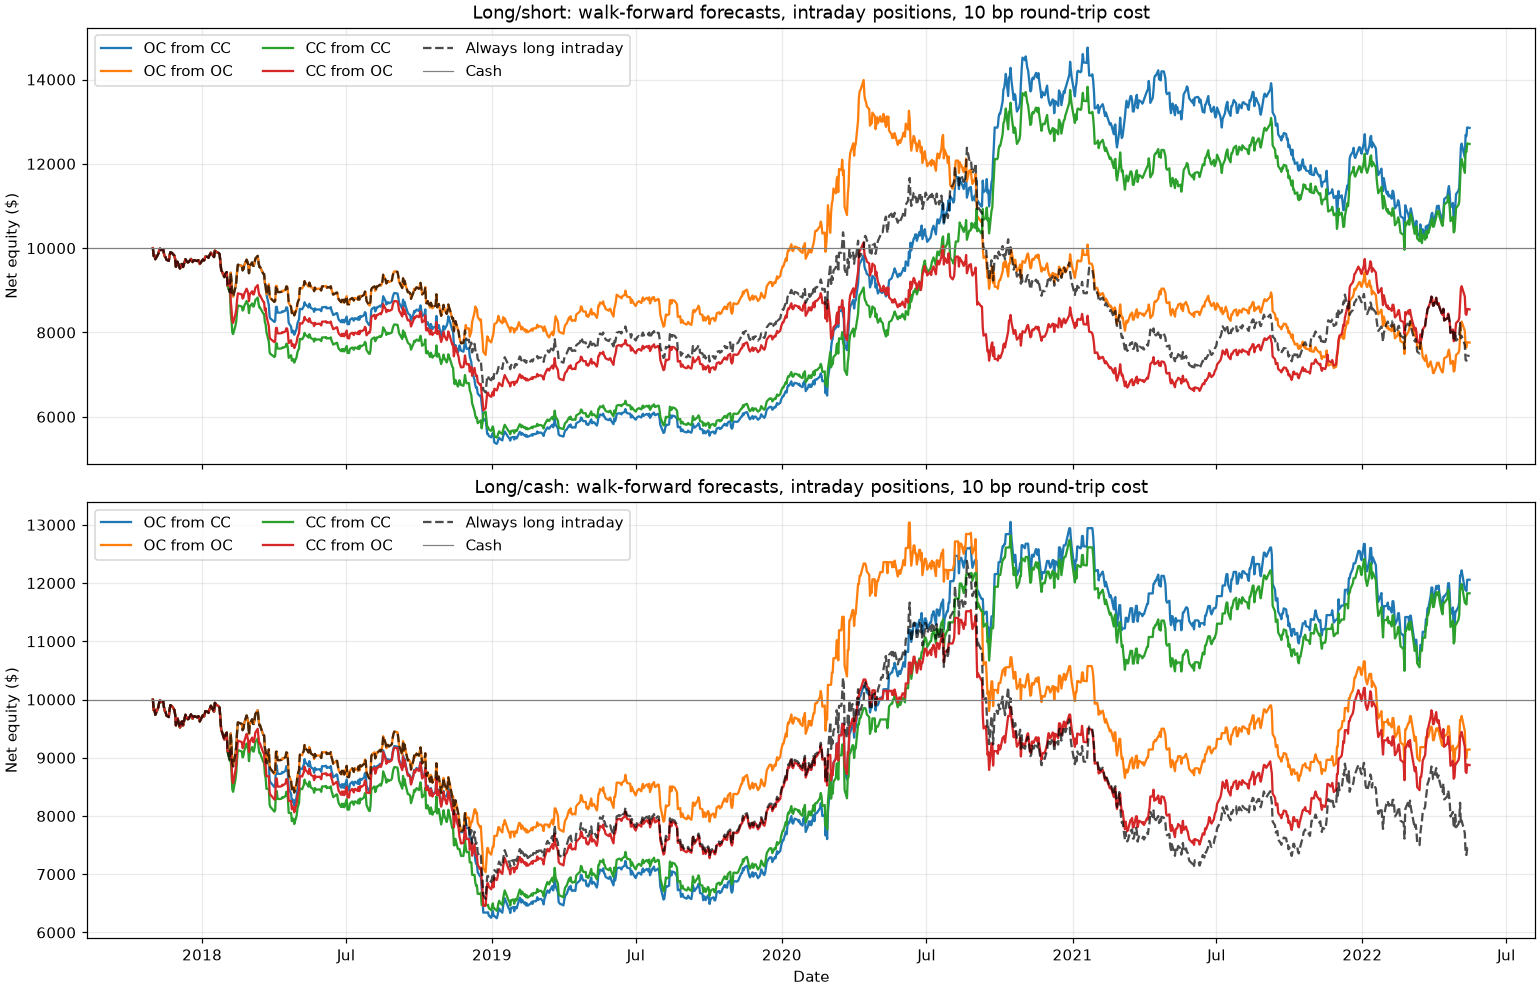

In [4]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

fig, axes = plt.subplots(2, 1, figsize=(14, 9), sharex=True, layout="constrained")
for ax, policy in zip(axes, ["Long/short", "Long/cash"]):
    for model in s2_specs:
        ledger = s2_ledgers[(model, policy)]
        # Include starting capital at the session before evaluation begins.
        baseline = s2_data.loc[s2_min_train - 1, "Date"]
        curve = pd.concat([pd.Series([s2_initial_capital], index=[baseline]), ledger["net_equity"]])
        ax.plot(curve.index, curve, label=model)
    reference = s2_ledgers[("Always long intraday", "Benchmark")]
    curve = pd.concat([pd.Series([s2_initial_capital], index=[baseline]), reference["net_equity"]])
    ax.plot(curve.index, curve, label="Always long intraday", color="black", linestyle="--", alpha=0.7)
    ax.axhline(s2_initial_capital, color="gray", linewidth=0.8, label="Cash")
    ax.set(title=f"{policy}: walk-forward forecasts, intraday positions, "
                 f"{s2_entry_cost_bps + s2_exit_cost_bps:g} bp round-trip cost", ylabel="Net equity ($)")
    ax.grid(alpha=0.25)
    ax.legend(ncol=3)
locator = mdates.AutoDateLocator(minticks=6, maxticks=12)
axes[-1].xaxis.set_major_locator(locator)
axes[-1].xaxis.set_major_formatter(mdates.ConciseDateFormatter(locator))
axes[-1].set_xlabel("Date")
plt.show()

### Later experiment: extended-hours movement

Investigate whether the return **from the regular-session close to the next pre-market opening time** predicts the next regular session's return. Define the exact pre-market time, exchange timezone, price convention (trade or quote/midpoint), and target interval before testing. Daily OHLC data cannot isolate this interval; timestamped extended-hours observations are required. A close-to-next-regular-open return includes the whole overnight period and is a different predictor.

Once extended-hours data are available, align sessions across weekends, holidays, and daylight-saving changes, and use only prices observable before the chosen entry time. Specify whether the target is open-to-close or close-to-close and evaluate it separately. If converting a closing-price prediction into an intraday signal at the open, the realized overnight gap is new information; simply subtracting it from a prior forecast is a candidate signal, not automatically an updated conditional forecast.

### Exploratory findings

All four models were evaluated over **1,142 common sessions**, from **2017-11-01 to 2022-05-16**, after an initial 252 paired observations. Each prediction was fitted on earlier sessions only.

| Model | Forecast OOS R² vs target mean | Intraday correlation | Net long/short return | Net long/cash return |
|---|---:|---:|---:|---:|
| OC from CC | +1.491% | +0.117 | +28.51% | +20.56% |
| OC from OC | +0.485% | +0.061 | -22.38% | -8.59% |
| CC from CC | +0.910% | +0.103 | +24.71% | +18.24% |
| CC from OC | -0.182% | +0.047 | -14.52% | -11.26% |

Always-long intraday returned **-25.58% net** on these same sessions under the same cost assumptions. Cash returned 0%.

The R² column compares each model with its own target’s expanding historical mean; it is not a measure of trading profitability. Negative values mean worse squared forecast error than that baseline. The trading columns use actual open-to-close returns for every model, including the close-to-close forecasters. Total trading returns are compounded over the full evaluation period, not annualized.

**Interpretation:** assess prediction improvement against the historical mean and net trading performance against the benchmark rows together. A profitable long-biased rule can benefit from positive intraday drift without useful return predictability. These estimates do not include significance tests or adjustment for selecting among multiple models and policies; no winner is established by its rank here. The sample was already used for exploration in Strategy 1. Keep separate test/final data untouched until a specification is frozen. Regenerate this findings cell if rerunning with changed data or settings.